In [1]:
#N1: imports + dataset path




import os
N_THREADS = 16                                   # 64 cores / 4 notebooks
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle
import numpy as np
import torch
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())

os.sched_setaffinity(0, range(0, 16))    # file 1
# os.sched_setaffinity(0, range(16, 32)) # file 2
# os.sched_setaffinity(0, range(32, 48)) # file 3
# os.sched_setaffinity(0, range(48, 64)) # file 4


import os, glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image
import time
import matplotlib.pyplot as plt

BASE = '/home/worker/Downloads/talha/week6/fruit notebooks/fruits-360/'   # folder that holds Training/ and Test/

TRAIN_DIR = os.path.join(BASE, 'Training')
TEST_DIR  = os.path.join(BASE, 'Test')
all_classes = sorted(os.listdir(TRAIN_DIR))

print(f"{len(all_classes)} classes")


threads: 16
268 classes


In [2]:
#N2: 70 problems x 3 classes (names match the folder names exactly)
# P1-P20 are the first 3 classes of the 20 groups used before; P21-P70 are new look-alike groups.
# 70 problems x 3 = 210 slots <= 268 classes, so every class is used in at most one problem (no sharing).

SCRIPT_NAMES = ["P1_apples", "P2_citrus", "P3_berries", "P4_tropical", "P5_vegetables",
                "P6_stone_pear", "P7_apples_red_gold", "P8_apples_other", "P9_cherries", "P10_grapes",
                "P11_citrus_2", "P12_pears_quince", "P13_flat_stone", "P14_berries_2", "P15_passion_exotic",
                "P16_tropical_2", "P17_small_exotic", "P18_roots", "P19_peppers", "P20_tomatoes",
                "P21_apples_3", "P22_apples_4", "P23_apples_named", "P24_apples_5", "P25_avocados",
                "P26_avocado_dark", "P27_blackberries", "P28_raspberries", "P29_strawberries", "P30_red_berries",
                "P31_cherries_2", "P32_cherries_3", "P33_cherries_4", "P34_cabbage", "P35_roots_2",
                "P36_green_veg", "P37_zucchini", "P38_cucumbers_1", "P39_cucumbers_2", "P40_cantaloupe",
                "P41_melons", "P42_carambola", "P43_papaya", "P44_pitahaya", "P45_cactus_fruit",
                "P46_odd_fruits", "P47_nuts_1", "P48_nuts_2", "P49_nuts_3", "P50_dates_fig",
                "P51_grapes_2", "P52_grapes_3", "P53_oranges", "P54_oranges_2", "P55_citrus_3",
                "P56_peaches", "P57_peaches_2", "P58_plums", "P59_pears_3", "P60_pears_4",
                "P61_pears_5", "P62_quince", "P63_peppers_2", "P64_peppers_3", "P65_tomatoes_2",
                "P66_tomatoes_3", "P67_tomatoes_4", "P68_mushrooms", "P69_onions_red", "P70_onions_mix"]

GROUP_FOLDERS = [
    ["Apple Braeburn 1", "Apple Golden 1", "Apple Granny Smith 1"],   # P1
    ["Clementine 1", "Grapefruit Pink 1", "Lemon 1"],   # P2
    ["Blueberry 1", "Cherry 1", "Raspberry 1"],   # P3
    ["Banana 1", "Kiwi 1", "Mango 1"],   # P4
    ["Eggplant 1", "Onion White 1", "Pepper Red 1"],   # P5
    ["Apricot 1", "Nectarine 1", "Peach 1"],   # P6
    ["Apple Red 1", "Apple Red 2", "Apple Golden 2"],   # P7
    ["Apple Crimson Snow 1", "Apple 5", "Apple 6"],   # P8
    ["Cherry Sour 1", "Cherry Wax Black 1", "Cherry Wax Red 1"],   # P9
    ["Grape 1", "Grape Pink 1", "Grape White 1"],   # P10
    ["Grapefruit White 1", "Lemon Meyer 1", "Mandarine 1"],   # P11
    ["Pear Abate 1", "Pear Monster 1", "Pear Williams 1"],   # P12
    ["Nectarine Flat 1", "Nectarine Flat 2", "Peach Flat 1"],   # P13
    ["Blackberry 1", "Mulberry 1", "Huckleberry 1"],   # P14
    ["Granadilla 1", "Maracuja 1", "Passion Fruit 1"],   # P15
    ["Banana Red 1", "Banana Lady Finger 1", "Mango Red 1"],   # P16
    ["Lychee 1", "Salak 1", "Physalis 1"],   # P17
    ["Potato White 1", "Potato Sweet 1", "Potato Red 2"],   # P18
    ["Pepper 2", "Pepper Green 1", "Pepper Red 3"],   # P19
    ["Tomato 4", "Tomato 11", "Tomato Cherry Red 1"],   # P20
    ["Apple 7", "Apple 8", "Apple 9"],   # P21
    ["Apple 10", "Apple 11", "Apple 12"],   # P22
    ["Apple Pink Lady 1", "Apple Red Delicious 1", "Apple Red 3"],   # P23
    ["Apple Red Yellow 1", "Apple Red Yellow 2", "Apple Golden 3"],   # P24
    ["Avocado 1", "Avocado 2", "Avocado Green 1"],   # P25
    ["Avocado Black 1", "Avocado Black 2", "Eggplant long 1"],   # P26
    ["Blackberry 2", "Blackberry 3", "Blackberry 5"],   # P27
    ["Raspberry 2", "Raspberry 3", "Raspberry 4"],   # P28
    ["Strawberry 1", "Strawberry 2", "Strawberry 3"],   # P29
    ["Redcurrant 1", "Strawberry Wedge 1", "Gooseberry 1"],   # P30
    ["Cherry 2", "Cherry 3", "Cherry 4"],   # P31
    ["Cherry Rainier 3", "Cherry Wax 1", "Cherry Wax 2"],   # P32
    ["Cherry Wax Red 2", "Cherry Wax Red 3", "Cherry Wax Yellow 1"],   # P33
    ["Cabbage red 1", "Cabbage white 1", "Cauliflower 1"],   # P34
    ["Beetroot 1", "Kohlrabi 1", "Carrot 1"],   # P35
    ["Celery 1", "Bean pod 1", "Cucumber 1"],   # P36
    ["Zucchini 1", "Zucchini dark 1", "Zucchini Green 1"],   # P37
    ["Cucumber 3", "Cucumber 4", "Cucumber 5"],   # P38
    ["Cucumber 6", "Cucumber 7", "Cucumber 8"],   # P39
    ["Cantaloupe 1", "Cantaloupe 2", "Cantaloupe 3"],   # P40
    ["Melon Piel de Sapo 1", "Watermelon 1", "Pomelo Sweetie 1"],   # P41
    ["Carambola 1", "Carambola 2", "Carambola 3"],   # P42
    ["Papaya 1", "Papaya 2", "Mangostan 1"],   # P43
    ["Pitahaya Red 1", "Pitahaya red 2", "Rambutan 1"],   # P44
    ["Cactus fruit 1", "Cactus fruit green 1", "Cactus fruit red 1"],   # P45
    ["Cherimoya 1", "Tamarillo 1", "Pepino 1"],   # P46
    ["Almonds 1", "Caju seed 1", "Chestnut 1"],   # P47
    ["Hazelnut 1", "Pistachio 1", "Walnut 1"],   # P48
    ["Cocos 1", "Nut Forest 1", "Nut Pecan 1"],   # P49
    ["Dates 1", "Dates 2", "Fig 1"],   # P50
    ["Grape White 2", "Grape White 3", "Grape White 4"],   # P51
    ["Grape Blue 1", "Grape pink 2", "Pomegranate 1"],   # P52
    ["Orange 1", "Orange 2", "Orange 3"],   # P53
    ["Orange 5", "orange 4", "Orange peeled 1"],   # P54
    ["Kumquats 1", "Tangelo 1", "Limes 1"],   # P55
    ["Peach 2", "Peach 3", "Peach 4"],   # P56
    ["Peach 5", "Peach 6", "Kaki 1"],   # P57
    ["Plum 1", "Plum 2", "Plum 3"],   # P58
    ["Pear 1", "Pear 2", "Pear 3"],   # P59
    ["Pear 8", "Pear 9", "Pear 10"],   # P60
    ["Pear 14", "Pear Forelle 1", "Pear Kaiser 1"],   # P61
    ["Quince 2", "Quince 3", "Quince 4"],   # P62
    ["Pepper 1", "Pepper Orange 1", "Pepper Orange 2"],   # P63
    ["Pepper Red 2", "Pepper Red 4", "Pepper Red 5"],   # P64
    ["Tomato 1", "Tomato 2", "Tomato 3"],   # P65
    ["Tomato 9", "Tomato 10", "Tomato Heart 1"],   # P66
    ["Tomato Maroon 1", "Tomato Maroon 2", "Tomato Cherry Maroon 1"],   # P67
    ["Mushroom champignon 1", "Mushroom champignon 2", "Mushroom champignon 3"],   # P68
    ["Onion Red 1", "Onion Red 2", "Onion Red 3"],   # P69
    ["Onion 2", "Onion White 2", "garlic bulb 1"],   # P70
]

missing = [f for grp in GROUP_FOLDERS for f in grp if f not in all_classes]
assert not missing, f"these folders don't exist: {missing}"
flat = [f for grp in GROUP_FOLDERS for f in grp]
assert len(set(flat)) == len(flat), "a class is used in more than one group"

for name, grp in zip(SCRIPT_NAMES, GROUP_FOLDERS):
    print(f"{name:20s} {grp}")
print(f"\n70 problems, 3 classes each, {len(set(flat))} different classes used, none twice ({len(all_classes) - len(flat)} of the {len(all_classes)} folders are not used)")


P1_apples            ['Apple Braeburn 1', 'Apple Golden 1', 'Apple Granny Smith 1']
P2_citrus            ['Clementine 1', 'Grapefruit Pink 1', 'Lemon 1']
P3_berries           ['Blueberry 1', 'Cherry 1', 'Raspberry 1']
P4_tropical          ['Banana 1', 'Kiwi 1', 'Mango 1']
P5_vegetables        ['Eggplant 1', 'Onion White 1', 'Pepper Red 1']
P6_stone_pear        ['Apricot 1', 'Nectarine 1', 'Peach 1']
P7_apples_red_gold   ['Apple Red 1', 'Apple Red 2', 'Apple Golden 2']
P8_apples_other      ['Apple Crimson Snow 1', 'Apple 5', 'Apple 6']
P9_cherries          ['Cherry Sour 1', 'Cherry Wax Black 1', 'Cherry Wax Red 1']
P10_grapes           ['Grape 1', 'Grape Pink 1', 'Grape White 1']
P11_citrus_2         ['Grapefruit White 1', 'Lemon Meyer 1', 'Mandarine 1']
P12_pears_quince     ['Pear Abate 1', 'Pear Monster 1', 'Pear Williams 1']
P13_flat_stone       ['Nectarine Flat 1', 'Nectarine Flat 2', 'Peach Flat 1']
P14_berries_2        ['Blackberry 1', 'Mulberry 1', 'Huckleberry 1']
P15_passion_ex

P1_apples            train  1464  test  488  train per class [492, 480, 492]
P2_citrus            train  1472  test  496  train per class [490, 490, 492]
P3_berries           train  1444  test  484  train per class [462, 492, 490]
P4_tropical          train  1446  test  488  train per class [490, 466, 490]
P5_vegetables        train  1572  test  524  train per class [468, 438, 666]
P6_stone_pear        train  1476  test  492  train per class [492, 492, 492]
P7_apples_red_gold   train  1476  test  492  train per class [492, 492, 492]
P8_apples_other      train  1357  test  451  train per class [444, 440, 473]
P9_cherries          train  1440  test  478  train per class [456, 492, 492]
P10_grapes           train  1451  test  485  train per class [469, 492, 490]
P11_citrus_2         train  1472  test  496  train per class [492, 490, 490]
P12_pears_quince     train  1470  test  498  train per class [490, 490, 490]
P13_flat_stone       train  1435  test  477  train per class [480, 463, 492]

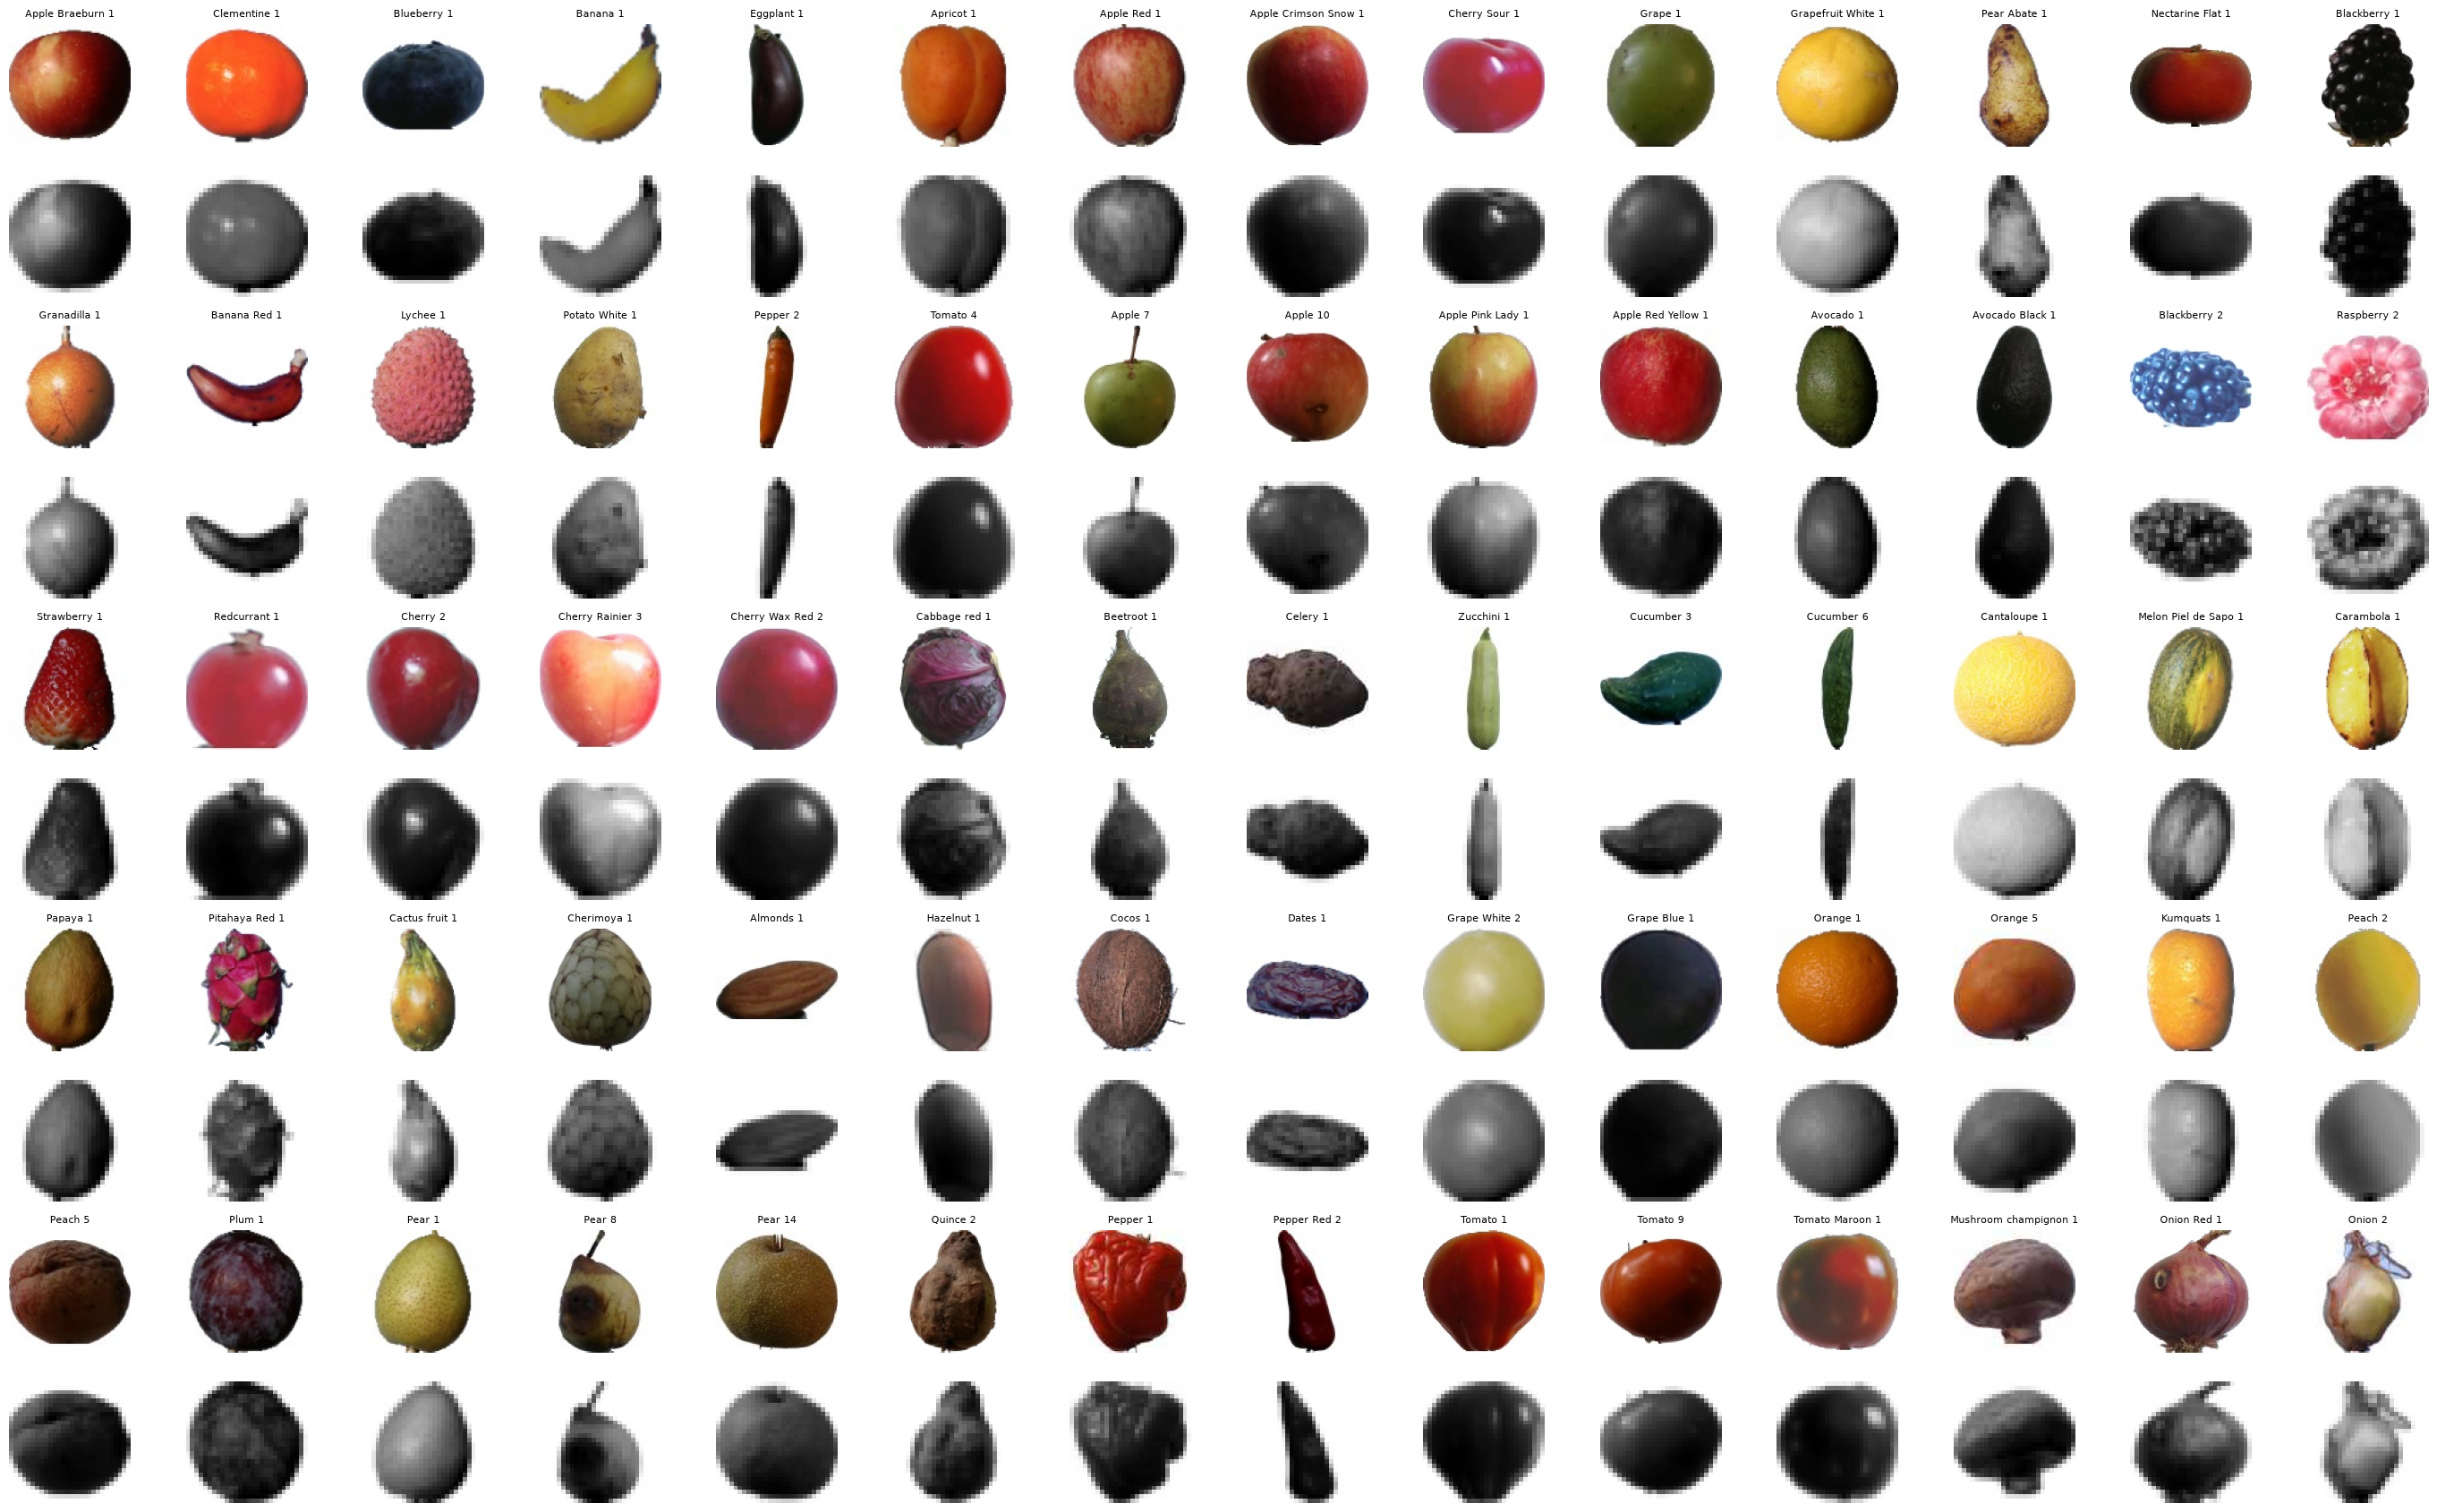

In [3]:
#N3: load images and convert to 28x28 grayscale (784 values per image, same format as EMNIST)
# Fruits-360 images are 100x100 colour photos on a white background, already upright.

def load_class(split_dir, folder):
    paths = sorted(glob.glob(os.path.join(split_dir, folder, '*')))
    arr = np.empty((len(paths), 784), dtype=np.uint8)
    for i, p in enumerate(paths):
        img = Image.open(p).convert('L').resize((28, 28), Image.BILINEAR)   # grayscale, 100x100 -> 28x28
        arr[i] = np.asarray(img, dtype=np.uint8).reshape(-1)
    return arr

t0 = time.time()
group_data = []      # per group: (x_train, y_train, x_test, y_test), labels 0-2 = position in the group list
for m, folders in enumerate(GROUP_FOLDERS):
    xs_tr, ys_tr, xs_te, ys_te = [], [], [], []
    for label, folder in enumerate(folders):
        a_tr = load_class(TRAIN_DIR, folder)
        a_te = load_class(TEST_DIR, folder)
        xs_tr.append(a_tr); ys_tr.append(np.full(len(a_tr), label, dtype=np.int64))
        xs_te.append(a_te); ys_te.append(np.full(len(a_te), label, dtype=np.int64))
    group_data.append((np.concatenate(xs_tr), np.concatenate(ys_tr),
                       np.concatenate(xs_te), np.concatenate(ys_te)))
    per_class = [len(x) for x in xs_tr]
    print(f"{SCRIPT_NAMES[m]:20s} train {len(group_data[m][0]):5d}  test {len(group_data[m][2]):4d}  "
          f"train per class {per_class}")
print(f"loaded in {time.time()-t0:.0f}s")

# visual check: one image per group, top = original colour, bottom = 28x28 grayscale (5 blocks of 14 groups)
fig, axes = plt.subplots(10, 14, figsize=(28, 17))
for m, folders in enumerate(GROUP_FOLDERS):
    r, c = 2 * (m // 14), m % 14
    p = sorted(glob.glob(os.path.join(TRAIN_DIR, folders[0], '*')))[0]
    axes[r, c].imshow(Image.open(p).convert('RGB')); axes[r, c].set_title(folders[0], fontsize=8)
    axes[r + 1, c].imshow(group_data[m][0][0].reshape(28, 28), cmap='gray')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()


In [4]:
#N4: building 70 datasets (standardized with each group's own training mean and std)

train_datasets = []
test_datasets  = []

for m in range(70):
    x_tr, y_tr, x_te, y_te = group_data[m]
    x_tr = torch.tensor(x_tr, dtype=torch.float32)
    x_te = torch.tensor(x_te, dtype=torch.float32)
    y_tr = torch.tensor(y_tr, dtype=torch.long)
    y_te = torch.tensor(y_te, dtype=torch.long)

    mean = x_tr.mean()
    std  = x_tr.std()
    x_tr = (x_tr - mean) / std
    x_te = (x_te - mean) / std

    train_datasets.append(TensorDataset(x_tr, y_tr))
    test_datasets.append(TensorDataset(x_te, y_te))

    print(f"{SCRIPT_NAMES[m]:20s} train {len(x_tr):5d}  test {len(x_te):4d}  "
          f"mean {x_tr.mean():.2f}  std {x_tr.std():.2f}")


P1_apples            train  1464  test  488  mean -0.00  std 1.00
P2_citrus            train  1472  test  496  mean 0.00  std 1.00
P3_berries           train  1444  test  484  mean -0.00  std 1.00
P4_tropical          train  1446  test  488  mean -0.00  std 1.00
P5_vegetables        train  1572  test  524  mean 0.00  std 1.00
P6_stone_pear        train  1476  test  492  mean 0.00  std 1.00
P7_apples_red_gold   train  1476  test  492  mean -0.00  std 1.00
P8_apples_other      train  1357  test  451  mean 0.00  std 1.00
P9_cherries          train  1440  test  478  mean -0.00  std 1.00
P10_grapes           train  1451  test  485  mean 0.00  std 1.00
P11_citrus_2         train  1472  test  496  mean 0.00  std 1.00
P12_pears_quince     train  1470  test  498  mean -0.00  std 1.00
P13_flat_stone       train  1435  test  477  mean 0.00  std 1.00
P14_berries_2        train  1432  test  480  mean -0.00  std 1.00
P15_passion_exotic   train  1470  test  498  mean -0.00  std 1.00
P16_tropical_2   

In [5]:
#N5: DataLoaders + settings

BATCH_SIZE = 32
train_loaders = [DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True) for ds in train_datasets]
test_loaders  = [DataLoader(ds, batch_size=256, shuffle=False)       for ds in test_datasets]

def infinite(loader):
    """Endless batches with a NEW shuffle on every pass (itertools.cycle would replay the first pass forever)."""
    while True:
        for batch in loader:
            yield batch

DEVICE          = 'cpu' if torch.cuda.is_available() else 'cpu'
INPUT_SIZE      = 784           # 28*28*1 grayscale
HIDDEN_SIZE     = 128
NUM_G_SETS      = 8
NUM_PROBLEMS    = 70
CLASSES_PER     = 3
TOTAL_CLASSES   = NUM_PROBLEMS * CLASSES_PER   # 210 slots = 210 different classes (no class is used twice)

LEARNING_RATE   = 0.001
MOMENTUM        = 0.9
NUM_EPOCHS      = 20
STEPS_PER_EPOCH = min(len(ds) for ds in train_datasets) // BATCH_SIZE   # one full pass of the smallest group
N_RUNS          = 30
EVAL_EVERY      = 5
PRINT_EVERY     = 5
a               = 1             # 0 = full switching (original compound), 1 = no switching

B_CONFIGS = torch.tensor([
    [1,1,1,1,a,a,a,a],   # P1
    [1,1,1,a,1,a,a,a],   # P2
    [1,1,1,a,a,1,a,a],   # P3
    [1,1,1,a,a,a,1,a],   # P4
    [1,1,1,a,a,a,a,1],   # P5
    [1,1,a,1,1,a,a,a],   # P6
    [1,1,a,1,a,1,a,a],   # P7
    [1,1,a,1,a,a,1,a],   # P8
    [1,1,a,1,a,a,a,1],   # P9
    [1,1,a,a,1,1,a,a],   # P10
    [1,1,a,a,1,a,1,a],   # P11
    [1,1,a,a,1,a,a,1],   # P12
    [1,1,a,a,a,1,1,a],   # P13
    [1,1,a,a,a,1,a,1],   # P14
    [1,1,a,a,a,a,1,1],   # P15
    [1,a,1,1,1,a,a,a],   # P16
    [1,a,1,1,a,1,a,a],   # P17
    [1,a,1,1,a,a,1,a],   # P18
    [1,a,1,1,a,a,a,1],   # P19
    [1,a,1,a,1,1,a,a],   # P20
    [1,a,1,a,1,a,1,a],   # P21
    [1,a,1,a,1,a,a,1],   # P22
    [1,a,1,a,a,1,1,a],   # P23
    [1,a,1,a,a,1,a,1],   # P24
    [1,a,1,a,a,a,1,1],   # P25
    [1,a,a,1,1,1,a,a],   # P26
    [1,a,a,1,1,a,1,a],   # P27
    [1,a,a,1,1,a,a,1],   # P28
    [1,a,a,1,a,1,1,a],   # P29
    [1,a,a,1,a,1,a,1],   # P30
    [1,a,a,1,a,a,1,1],   # P31
    [1,a,a,a,1,1,1,a],   # P32
    [1,a,a,a,1,1,a,1],   # P33
    [1,a,a,a,1,a,1,1],   # P34
    [1,a,a,a,a,1,1,1],   # P35
    [a,1,1,1,1,a,a,a],   # P36
    [a,1,1,1,a,1,a,a],   # P37
    [a,1,1,1,a,a,1,a],   # P38
    [a,1,1,1,a,a,a,1],   # P39
    [a,1,1,a,1,1,a,a],   # P40
    [a,1,1,a,1,a,1,a],   # P41
    [a,1,1,a,1,a,a,1],   # P42
    [a,1,1,a,a,1,1,a],   # P43
    [a,1,1,a,a,1,a,1],   # P44
    [a,1,1,a,a,a,1,1],   # P45
    [a,1,a,1,1,1,a,a],   # P46
    [a,1,a,1,1,a,1,a],   # P47
    [a,1,a,1,1,a,a,1],   # P48
    [a,1,a,1,a,1,1,a],   # P49
    [a,1,a,1,a,1,a,1],   # P50
    [a,1,a,1,a,a,1,1],   # P51
    [a,1,a,a,1,1,1,a],   # P52
    [a,1,a,a,1,1,a,1],   # P53
    [a,1,a,a,1,a,1,1],   # P54
    [a,1,a,a,a,1,1,1],   # P55
    [a,a,1,1,1,1,a,a],   # P56
    [a,a,1,1,1,a,1,a],   # P57
    [a,a,1,1,1,a,a,1],   # P58
    [a,a,1,1,a,1,1,a],   # P59
    [a,a,1,1,a,1,a,1],   # P60
    [a,a,1,1,a,a,1,1],   # P61
    [a,a,1,a,1,1,1,a],   # P62
    [a,a,1,a,1,1,a,1],   # P63
    [a,a,1,a,1,a,1,1],   # P64
    [a,a,1,a,a,1,1,1],   # P65
    [a,a,a,1,1,1,1,a],   # P66
    [a,a,a,1,1,1,a,1],   # P67
    [a,a,a,1,1,a,1,1],   # P68
    [a,a,a,1,a,1,1,1],   # P69
    [a,a,a,a,1,1,1,1],   # P70
], dtype=torch.float32).to(DEVICE)

print(f"Device: {DEVICE}")
print(f"Runs: {N_RUNS}  Epochs: {NUM_EPOCHS}  Steps/epoch: {STEPS_PER_EPOCH}")
print(f"Both train loss and test loss = avg CE per problem  (3-way random guess = ln3 = {np.log(3):.3f})")


Device: cpu
Runs: 30  Epochs: 20  Steps/epoch: 23
Both train loss and test loss = avg CE per problem  (3-way random guess = ln3 = 1.099)


In [6]:
#N9: MODEL 4: COMPOUND SYNAPSE
# 8 G sets hidden + 8 G sets output. Same b picks 4-of-8 in both.
# 8 * [784*128 + 128*3] = 8 * 100,736 = 805,888 parameters
# (architecture identical to the EMNIST/CIFAR versions)

accs_compound    = []
trloss_compound  = []
teloss_compound  = []
tracc_compound   = []   # train accuracy per run

print("Training COMPOUND SYNAPSE on Fruits-360 (70 groups x 3 classes, 8 G sets)...")
print(f"{'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Te loss':>8} | {'Tr acc':>7} {'Te acc':>7} | "
      + " ".join(f"{'P'+str(i+1):>5}" for i in range(70)))
print("-" * 475)
t0 = time.time()

for run in range(N_RUNS):

    Ghid_comp = nn.Parameter(torch.empty(8, HIDDEN_SIZE, INPUT_SIZE, device=DEVICE))
    Gout_comp = nn.Parameter(torch.empty(8, CLASSES_PER, HIDDEN_SIZE, device=DEVICE))
    for n in range(8):
        nn.init.kaiming_normal_(Ghid_comp.data[n], mode="fan_in", nonlinearity="relu")
        nn.init.kaiming_normal_(Gout_comp.data[n], mode="fan_in", nonlinearity="relu")

    optimizer_comp = torch.optim.SGD([Ghid_comp, Gout_comp], lr=LEARNING_RATE, momentum=MOMENTUM)
    inf_iters_comp = [infinite(loader) for loader in train_loaders]   # reshuffles every pass
    last_tr_loss   = 0.0

    for epoch in range(NUM_EPOCHS):
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            optimizer_comp.zero_grad()
            total_loss = torch.zeros((), device=DEVICE)
            for m in range(70):
                x, y = next(inf_iters_comp[m])
                x, y = x.to(DEVICE), y.to(DEVICE)
                b    = B_CONFIGS[m]

                scale = (4 + 4*a**2) ** 0.5     # 4 G sets on: a=0 gives 2.0, a=1 gives 2.828
                W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
                Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
                h    = F.relu(x @ W.T)
                out  = h @ Wout.T
                total_loss = total_loss + F.cross_entropy(out, y)
                tr_correct += (out.argmax(1) == y).sum().item()
                tr_total   += y.size(0)
            total_loss.backward()
            optimizer_comp.step()
            epoch_loss += total_loss.item()

        avg_tr       = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        last_tr_loss = avg_tr
        tr_acc       = tr_correct / tr_total * 100

        if (epoch + 1) % EVAL_EVERY == 0:
            ep_accs    = []
            ep_te_loss = 0.0
            with torch.no_grad():
                for m in range(70):
                    correct = total = 0
                    m_loss  = n_bat = 0.0
                    b    = B_CONFIGS[m]

                    scale = (4 + 4*a**2) ** 0.5
                    W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
                    Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
                    for x, y in test_loaders[m]:
                        x, y    = x.to(DEVICE), y.to(DEVICE)
                        out     = F.relu(x @ W.T) @ Wout.T
                        correct += (out.argmax(1) == y).sum().item()
                        total   += y.size(0)
                        m_loss  += F.cross_entropy(out, y).item()
                        n_bat   += 1
                    ep_accs.append(correct / total * 100)
                    ep_te_loss += m_loss / n_bat
            avg_te = ep_te_loss / NUM_PROBLEMS

            if (run + 1) % PRINT_EVERY == 0:
                acc_str = " ".join(f"{acc:5.1f}" for acc in ep_accs)
                print(f"{run+1:4d} {epoch+1:4d} | {avg_tr:8.4f} {avg_te:8.4f} | "
                      f"{tr_acc:6.2f}% {np.mean(ep_accs):6.2f}% | {acc_str}")

    run_accs    = []
    run_te_loss = 0.0
    with torch.no_grad():
        for m in range(70):
            correct = total = 0
            m_loss  = n_bat = 0.0
            b    = B_CONFIGS[m]

            scale = (4 + 4*a**2) ** 0.5
            W    = torch.einsum('n,nhi->hi', b, Ghid_comp)/scale
            Wout = torch.einsum('n,noh->oh', b, Gout_comp)/scale
            for x, y in test_loaders[m]:
                x, y    = x.to(DEVICE), y.to(DEVICE)
                out     = F.relu(x @ W.T) @ Wout.T
                correct += (out.argmax(1) == y).sum().item()
                total   += y.size(0)
                m_loss  += F.cross_entropy(out, y).item()
                n_bat   += 1
            run_accs.append(correct / total * 100)
            run_te_loss += m_loss / n_bat

    accs_compound.append(run_accs)
    trloss_compound.append(last_tr_loss)
    tracc_compound.append(tr_acc)
    teloss_compound.append(run_te_loss / NUM_PROBLEMS)

    if (run + 1) % PRINT_EVERY == 0:
        print(f"  \u2192 run {run+1}  train acc {tr_acc:.2f}%  test acc {np.mean(run_accs):.2f}%  "
              f"tr loss {last_tr_loss:.4f}  te loss {run_te_loss/NUM_PROBLEMS:.4f}  [{time.time()-t0:.0f}s]\n")

print(f"\nCOMPOUND DONE:  "
      f"train acc {np.mean(tracc_compound):.2f}% \u00B1 {np.std(tracc_compound):.2f}%  |  "
      f"test acc {np.mean([np.mean(r) for r in accs_compound]):.2f}% \u00B1 "
      f"{np.std([np.mean(r) for r in accs_compound]):.2f}%  |  "
      f"train loss {np.mean(trloss_compound):.4f}  test loss {np.mean(teloss_compound):.4f}\n")


Training COMPOUND SYNAPSE on Fruits-360 (70 groups x 3 classes, 8 G sets)...
 Run   Ep |  Tr loss  Te loss |  Tr acc  Te acc |    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11   P12   P13   P14   P15   P16   P17   P18   P19   P20   P21   P22   P23   P24   P25   P26   P27   P28   P29   P30   P31   P32   P33   P34   P35   P36   P37   P38   P39   P40   P41   P42   P43   P44   P45   P46   P47   P48   P49   P50   P51   P52   P53   P54   P55   P56   P57   P58   P59   P60   P61   P62   P63   P64   P65   P66   P67   P68   P69   P70
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------